# Transformers

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow import keras

In [ ]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask

# class PositionalEmbedding(layers.Layer):
#     def __init__(self, sequence_length, output_dim, **kwargs):
#         super().__init__(**kwargs)
#         self.position_embeddings = layers.Embedding(
#             input_dim=sequence_length, output_dim=output_dim
#         )
#         self.sequence_length = sequence_length
#         self.output_dim = output_dim
#
#     def call(self, inputs):
#         # The inputs are of shape: `(batch_size, frames, num_features)`
#         length = tf.shape(inputs)[1]
#         batch_size = tf.shape(inputs)[0]
#         positions = tf.range(start=0, limit=length, delta=1)
#
#         # Embedding is applied separately to each frame in the batch
#         embedded_positions_list = []
#         for i in range(batch_size):
#             embedded_positions = self.position_embeddings(positions)
#             embedded_positions_list.append(embedded_positions)
#
#         embedded_positions_batch = tf.stack(embedded_positions_list, axis=0)
#         return inputs + embedded_positions_batch
#
#     def compute_mask(self, inputs, mask=None):
#         mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
#         return mask


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim, dropout=0.3
        )
        self.dense_proj = keras.Sequential(
            [layers.Dense(dense_dim, activation=tf.nn.gelu), layers.Dense(embed_dim),]
        )
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(inputs, inputs, attention_mask=mask)
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)


class SignalAnalyser(tf.keras.layers.Layer):
    def __init__(self, sequence_length, embed_dim, **kwargs):
        super(SignalAnalyser, self).__init__(**kwargs)
        self.positional_embedding = PositionalEmbedding(
            sequence_length, embed_dim, name="frame_position_embedding"
        )
        self.transformer = TransformerEncoder(
            embed_dim, 256, 4, name="transformer_encoder"
        )
        self.global_average_pooling = tf.keras.layers.GlobalAveragePooling1D()
        self.reshape = tf.keras.layers.Reshape((16, 16, 1))
    def call(self, inputs):
        x = layers.Reshape((100, 256))(inputs)
        x = self.positional_embedding(x)
        x = self.transformer(x)
        x = self.global_average_pooling(x)
        x = self.reshape(x)
        return x

def signal_analyser(sequence_length=100, embed_dim=256):
    dense_dim = 4
    num_heads = 1

    inputs = keras.Input(shape=(None, None))
    x = layers.Reshape((100, 256))(inputs)
    x = PositionalEmbedding(
        sequence_length, embed_dim, name="frame_position_embedding"
    )(x)
    x = TransformerEncoder(embed_dim, dense_dim, num_heads, name="transformer_layer")(x)
    x = layers.GlobalMaxPooling1D()(x)
    outputs = layers.Dense(5, activation="linear")(x)

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [ ]:
# Exemplo de uso
input_shape = (8, 100, 16, 16, 1)  # (batch, janelas, altura, largura, canal)

# Criar uma instância da classe SignalAnalyzer
analyser = signal_analyser()

# Gerar dados de exemplo
inputs = tf.random.normal(input_shape)

# Realizar a análise e remontar o sinal
output = analyser(inputs)

# Verificar a dimensão do sinal remontado
print(output.shape)

input:  (None, None, None)
PositionalEmbedding:  (None, 100, 256)
TransformerEncoder:  (None, 100, 256)
GlobalMaxPooling1D:  (None, 256)
(8, 16, 16, 1)


# Autoencoder

In [ ]:
!pip install -q einops remotezip tensorflow_addons
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 612.1/612.1 kB 30.5 MB/s eta 0:00:00
done!


In [ ]:
import remotezip as rz
import einops

import tensorflow as tf
import keras
from keras import layers

In [ ]:
class ResidualMain(keras.layers.Layer):
  """
    Residual block of the model with convolution, layer normalization, and
    the activation function, ReLU.
  """
  def __init__(self, filters, kernel_size):
    super().__init__()
    self.seq = keras.Sequential([
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization(),
        layers.ReLU(),
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization()
    ])

  def call(self, x):
    # x = tf.expand_dims(x, -2)  # Add a new channel axis
    return self.seq(x)


class Project(keras.layers.Layer):
  """
    Project certain dimensions of the tensor as the data is passed through
    different sized filters and downsampled.
  """
  def __init__(self, units):
    super().__init__()
    self.seq = keras.Sequential([
        layers.Dense(units),
        layers.LayerNormalization()
    ])

  def call(self, x):
    return self.seq(x)


def add_residual_block(input, filters, kernel_size):
  """
    Add residual blocks to the model. If the last dimensions of the input
    data and filter size does not match, project it such that last
    dimension matches.
  """
  out = ResidualMain(filters,
                     kernel_size)(input)

  res = input
  # Using the Keras functional APIs, project the last dimension of the
  # tensor to match the new filter size
  if out.shape[-1] != input.shape[-1]:
    res = Project(out.shape[-1])(res)

  return layers.add([res, out])


class ResizeSignal(keras.layers.Layer):
  def __init__(self, height, width):
    super().__init__()
    self.height = height
    self.width = width
    self.resizing_layer = layers.Resizing(self.height, self.width)

  def call(self, signal):
    """
      Use the einops library to resize the tensor.

      Args:
        Signal: Tensor representation of the signal, in the form of a set
        of frames.

      Return:
        A downsampled size of the signal according to the new height and
        width it should be resized to.
    """
    # b stands for batch size, t stands for time, h stands for height,
    # w stands for width, and c stands for the number of channels.
    old_shape = einops.parse_shape(signal, 'b t h w c')
    images = einops.rearrange(signal, 'b t h w c -> (b t) h w c')
    images = self.resizing_layer(images)
    signals = einops.rearrange(
        images, '(b t) h w c -> b t h w c',
        t = old_shape['t'])
    return signals

In [ ]:
class Conv2Plus1D(keras.layers.Layer):
    def __init__(self, filters, kernel_size, padding, activation='linear', dilation_rate=1, **kwargs):
        """
          A sequence of convolutional layers that first apply the convolution
          operation over the spatial dimensions, and then the temporal
          dimension.
        """
        super().__init__(**kwargs)
        self.spatial_conv = layers.Conv3D(filters=filters,
                                          kernel_size=(1, kernel_size[1], kernel_size[2]),
                                          padding=padding,
                                          activation=activation,
                                          dilation_rate=(1, dilation_rate, dilation_rate))
        self.temporal_conv = layers.Conv3D(filters=filters,
                                          kernel_size=(kernel_size[0], 1, 1),
                                          padding=padding,
                                          activation=activation,
                                          dilation_rate=(dilation_rate, 1, 1))
        self.batch_norm = layers.BatchNormalization()

    def call(self, x):
        x = self.spatial_conv(x)
        x = self.temporal_conv(x)
        x = self.batch_norm(x)
        x = tf.keras.activations.relu(x)
        return x

class DilatedConv2Plus1D(tf.keras.layers.Layer):
    """
    The dilation rate is set as an attribute and determines the spacing
     between the kernel elements during convolution, allowing for an
     increased receptive field.
    """
    def __init__(self, dilation_rate, filters, kernel_size, **kwargs):
        super().__init__(**kwargs)
        self.conv2plus1d = Conv2Plus1D(filters=filters, kernel_size=kernel_size, padding="same")
        self.batchnorm = tf.keras.layers.BatchNormalization()
        self.dilation_rate = dilation_rate  # save dilation_rate as an attribute

    def call(self, x):
        x = self.conv2plus1d(x)
        x = self.batchnorm(x)
        x = tf.keras.activations.relu(x)
        return x


class Estimatior(tf.keras.Model):
    """
    The Estimatior class is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """

    def __init__(self, num_blocks, num_layers, filters, kernel_size, dilations, input_shape_, num_lstm_blocks, **kwargs):
        super(Estimatior, self).__init__(**kwargs)
        self.num_blocks = num_blocks
        self.num_layers = num_layers
        self.filters = filters
        self.kernel_size = kernel_size
        self.dilations = dilations
        self.input_shape_ = input_shape_
        self.num_lstm_blocks = num_lstm_blocks

        # Build the model
        self.build_model()

    def build_model(self):
        # Define input layer
        inputs = tf.keras.Input(shape=self.input_shape_)

        # Build Estimatior blocks
        x = inputs
        for i in range(self.num_blocks):
            for j in range(self.num_layers):
                dilation_rate = self.dilations[j % len(self.dilations)]
                x = DilatedConv2Plus1D(dilation_rate=dilation_rate, filters=self.filters, kernel_size=self.kernel_size)(x)
        x = tf.keras.layers.ELU()(x)

        # Add residual blocks
        for i in range(self.num_blocks):
            x = add_residual_block(x, self.filters, (18, 3, 3))
            x = ResizeSignal(x.shape[2] // 4, x.shape[3] // 4)(x)
        x = tf.keras.layers.GlobalAveragePooling3D()(x)
        x = tf.keras.layers.Flatten()(x)

        # Output layer
        outputs = tf.keras.layers.Dense(1, activation="linear")(x)

        # Create the model
        self.model = tf.keras.Model(inputs=inputs, outputs=outputs)

    def call(self, inputs):
        return self.model(inputs)

    def summary(self):
        self.model.summary()

    def plot_model(self, show_shapes=False):
        tf.keras.utils.plot_model(
            self.model,
            show_shapes=show_shapes
        )


def encoder(num_blocks, num_layers, filters, kernel_size, dilations, input_shape_):
    """
    The encoder function is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)

    # Build encoder blocks
    x = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            x = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(x)
    x = layers.ELU()(x)
    # Add residual blocks
    for i in range(num_blocks):
        x = add_residual_block(x, filters, (18, 3, 3))
        x = ResizeSignal(x.shape[2] // 4, x.shape[3] // 4)(x)
    # Create the Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=x)

    return model

def estimator(input_shape_=[100, 1, 1, 16]):
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)
    # Build encoder blocks
    x = layers.GlobalAveragePooling3D()(input_layer)
    x = layers.Flatten()(x)
    x = layers.ReLU()(x)
    # Linear combinator layer
    x = layers.Dense(1, activation="linear")(x)
    # Create the Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=x)

    return model

def decoder(num_blocks, num_layers, filters, kernel_size, dilations, input_shape_):
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)
    # Build decoder blocks
    x = input_layer
    for i in range(num_blocks):
        x = add_residual_block(x, filters, (18, 3, 3))
        x = ResizeSignal(x.shape[2] * 4, x.shape[3] * 4)(x)
    x = layers.ELU()(x)
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            x = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(x)
    x = Conv2Plus1D(1, (18, 3, 3), padding="same")(x)
    # Create the Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=x)

    return model

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Layer


class OSELM(tf.keras.layers.Layer):
    def __init__(self, input_size, output_size, hidden_layer_size, regularization=0, random_state=None, **kwargs):
        super(OSELM, self).__init__(**kwargs)
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layer_size = hidden_layer_size
        self.regularization = regularization
        self.random_state = random_state
        self.input_weights = None
        self.bias = None
        self.output_weights = None
        self.H = None
        self.beta = None

        # Define the kernel attribute
        self.kernel = tf.keras.layers.Dense(hidden_layer_size + 1, use_bias=False)

    def build(self, input_shape):
        input_size = input_shape[-1]
        self.input_weights = self.add_weight(shape=(input_size, self.hidden_layer_size),
                                             initializer='uniform',
                                             trainable=True)
        self.bias = self.add_weight(shape=(self.hidden_layer_size,),
                                    initializer='uniform',
                                    trainable=True)
        self.output_weights = self.add_weight(shape=(self.hidden_layer_size + 1, self.output_size),
                                              initializer='uniform',
                                              trainable=True)
        super(OSELM, self).build(input_shape)

    def call(self, inputs):
        if self.input_weights is None or self.bias is None or self.output_weights is None:
            raise RuntimeError("OS-ELM layer has not been built.")

        H = self.relu(tf.cast(tf.matmul(inputs, self.input_weights) + self.bias, tf.float32))
        H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
        output = tf.matmul(H, self.output_weights)
        return output

    def call(self, inputs, outputs_1=0, flag=False):
        if self.input_weights is None or self.bias is None or self.output_weights is None:
            raise RuntimeError("TFOS_ELM layer has not been built.")

        H = self.relu(tf.cast(tf.matmul(inputs, self.input_weights) + self.bias, tf.float32))
        H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
        output = tf.matmul(H, self.output_weights)
        loss_value = 0

        if flag:
            # Set the loss function
            loss = tf.keras.losses.MeanSquaredError()

            # Compute the loss
            loss_value = loss(output, outputs_1)

        return output, loss_value

    def relu(self, x):
        return tf.maximum(0.0, tf.cast(x, tf.float32))

    def get_config(self):
        config = super(OSELM, self).get_config()
        config.update({
            'input_size': self.input_size,
            'output_size': self.output_size,
            'hidden_layer_size': self.hidden_layer_size,
            'regularization': self.regularization,
            'random_state': self.random_state,
        })
        return config

In [ ]:
def autoencoder(num_blocks, num_layers, filters, kernel_size, dilations, input_shape_):
    oselm = OSELM(input_size=16, output_size=1, hidden_layer_size=128)
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)

    # Encoder
    encoder_output = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            encoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(encoder_output)
    encoder_output = layers.ELU()(encoder_output)
    for i in range(num_blocks):
        encoder_output = add_residual_block(encoder_output, filters, (18, 3, 3))
        encoder_output = ResizeSignal(encoder_output.shape[2] // 4, encoder_output.shape[3] // 4)(encoder_output)

    # Estimator
    estimator_output = layers.GlobalAveragePooling3D()(encoder_output)
    estimator_output = layers.Flatten()(estimator_output)
    estimator_output, _ = oselm(estimator_output, flag=True)

    # Decoder
    decoder_output = encoder_output
    for i in range(num_blocks):
        decoder_output = add_residual_block(decoder_output, filters, (18, 3, 3))
        decoder_output = ResizeSignal(decoder_output.shape[2] * 4, decoder_output.shape[3] * 4)(decoder_output)
    decoder_output = layers.ELU()(decoder_output)
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            decoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(decoder_output)
    decoder_output = Conv2Plus1D(1, (18, 3, 3), padding="same")(decoder_output)

    # Passa o decoder_output novamente pelo encoder_model
    latent = encoder_model(decoder_output)
    latent = layers.GlobalAveragePooling3D()(latent)

    # Segunda passada pela OSELM usando o erro da primeira passada
    second_pass_output, _ = oselm(latent, estimator_output, flag=True)

    # Cria o Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=[estimator_output, decoder_output, second_pass_output])

    return model

In [ ]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
input_shapeA = [100, 16, 16, 1]
input_shapeB = [100, 1, 1, 16]

encoder_model = encoder(
    num_blocks=2, num_layers=3, filters=16,
    kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shapeA,
)
decoder_model = decoder(
    num_blocks=2, num_layers=3, filters=16,
    kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shapeB,
)


autoencoder_model = autoencoder(
    num_blocks=2, num_layers=3, filters=16,
    kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shapeA,
)

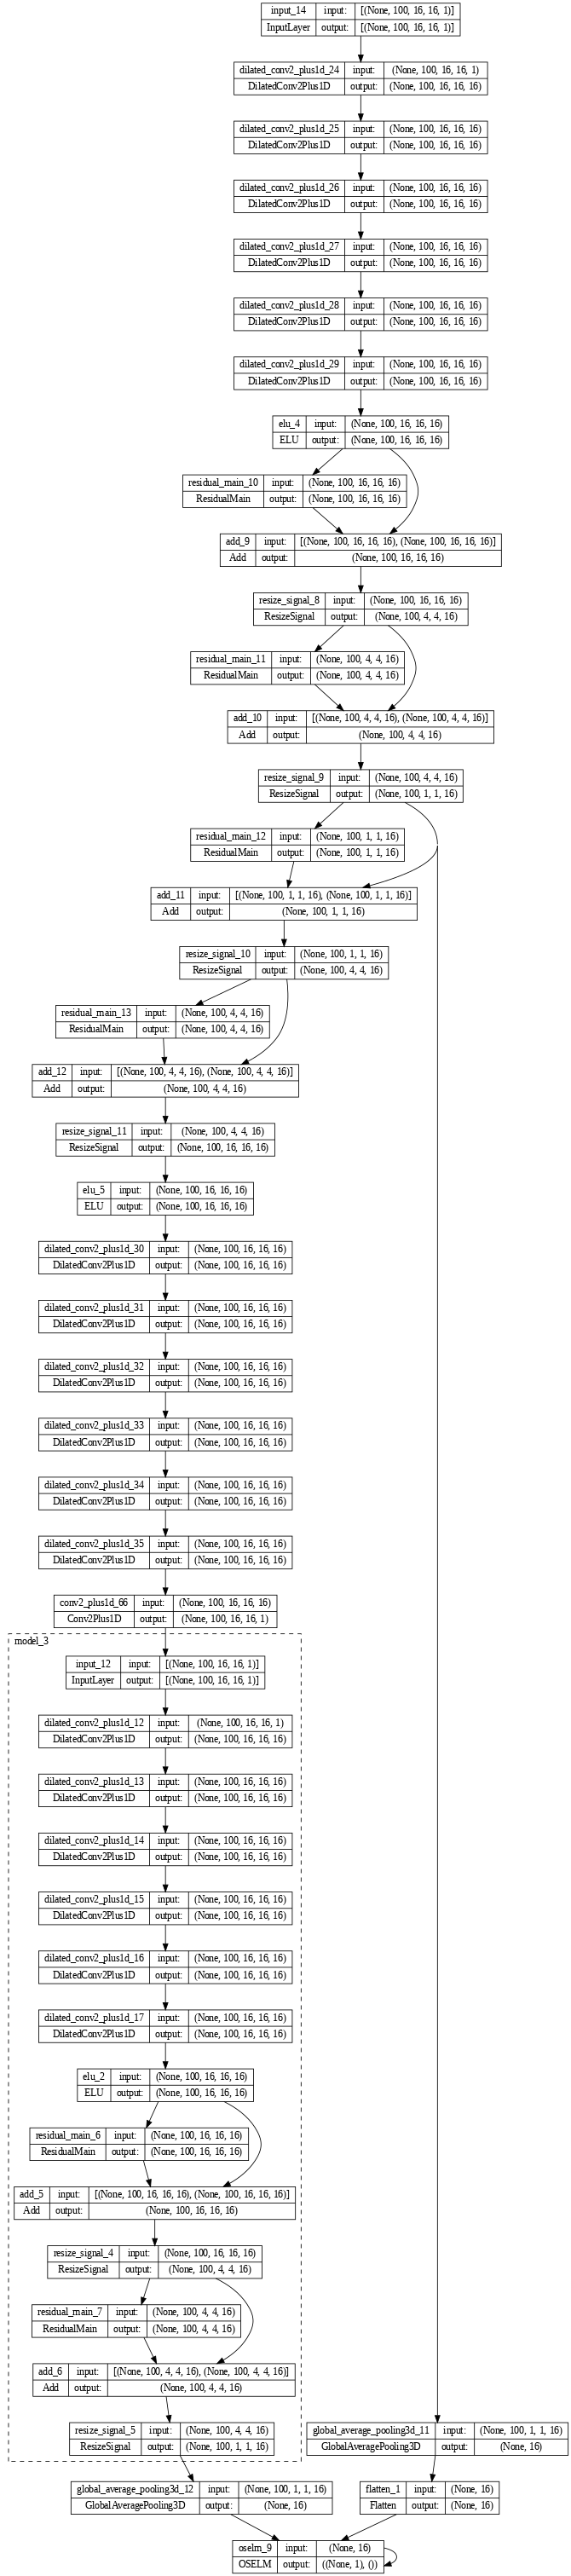

In [ ]:
keras.utils.plot_model(autoencoder_model, expand_nested=True, dpi=60, show_shapes=True)

In [ ]:
autoencoder_model.summary()

Model: "model_5"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_14 (InputLayer)          [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d_24 (Dilat  (None, 100, 16, 16,  4912       ['input_14[0][0]']               
 edConv2Plus1D)                  16)                                                              
                                                                                                  
 dilated_conv2_plus1d_25 (Dilat  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d_24[0][0]']
 edConv2Plus1D)                  16)                                                        

In [ ]:
def autoencoder_v2(num_blocks, num_layers, filters, kernel_size, dilations, input_shape_):
    oselm = OSELM(input_size=16, output_size=1, hidden_layer_size=128)
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)


    #################################################
    # Primeira Passada, não ocorrerá no modelo final#
    #################################################
    # Encoder
    encoder_output = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            encoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(encoder_output)
    encoder_output = layers.ELU()(encoder_output)
    for i in range(num_blocks):
        encoder_output = add_residual_block(encoder_output, filters, (18, 3, 3))
        encoder_output = ResizeSignal(encoder_output.shape[2] // 4, encoder_output.shape[3] // 4)(encoder_output)

    # Decoder
    decoder_output = encoder_output
    for i in range(num_blocks):
        decoder_output = add_residual_block(decoder_output, filters, (18, 3, 3))
        decoder_output = ResizeSignal(decoder_output.shape[2] * 4, decoder_output.shape[3] * 4)(decoder_output)
    decoder_output = layers.ELU()(decoder_output)
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            decoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(decoder_output)
    decoder_output = Conv2Plus1D(1, (18, 3, 3), padding="same")(decoder_output)
    #Signal Analyzer
    # Criar uma instância da classe SignalAnalyzer
    analyser = signal_analyser()
    # Realizar a análise e remontar o sinal
    diff = tf.subtract(input_layer, decoder_output)
    diff = layers.Reshape((100, 256))(diff)
    analyser_layer = analyser(diff)
    analyser_layer = layers.Reshape((1, 16, 16, 1))(analyser_layer)
    analyser_layer = add_residual_block(analyser_layer, 100, (18, 3, 3))
    analyser_layer = layers.Reshape((100, 16, 16, 1))(analyser_layer)
    analyser_layer = add_residual_block(analyser_layer, 16, (18, 3, 3))
    # analyser_layer = tf.broadcast_to(analyser_layer, decoder_output.shape)
    #################################################
    # Final da Primeira Passada                     #
    #################################################


    # Encoder
    encoder_output = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            encoder_output = layers.Add()([encoder_output, analyser_layer])  # Adicionar o analyser_layer como resíduo
            dilation_rate = dilations[j % len(dilations)]
            encoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(encoder_output)

    encoder_output = layers.ELU()(encoder_output)
    for i in range(num_blocks):
        encoder_output = add_residual_block(encoder_output, filters, (18, 3, 3))
        encoder_output = ResizeSignal(encoder_output.shape[2] // 4, encoder_output.shape[3] // 4)(encoder_output)

    # Estimator
    estimator_output = layers.GlobalAveragePooling3D()(encoder_output)
    estimator_output = layers.Flatten()(estimator_output)
    estimator_output, _ = oselm(estimator_output, flag=True)

    # Decoder
    decoder_output = encoder_output
    for i in range(num_blocks):
        decoder_output = add_residual_block(decoder_output, filters, (18, 3, 3))
        decoder_output = ResizeSignal(decoder_output.shape[2] * 4, decoder_output.shape[3] * 4)(decoder_output)
    decoder_output = layers.ELU()(decoder_output)
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            decoder_output = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(decoder_output)
            decoder_output = layers.Add()([decoder_output, analyser_layer])  # Adicionar o analyser_layer como resíduo
    decoder_output = Conv2Plus1D(1, (18, 3, 3), padding="same")(decoder_output)

    # Passa o decoder_output novamente pelo encoder_model
    # latent = encoder_model(decoder_output)
    latent = decoder_output
    for i in range(num_blocks):
        for j in range(num_layers):
            latent = layers.Add()([latent, analyser_layer])  # Adicionar o analyser_layer como resíduo
            dilation_rate = dilations[j % len(dilations)]
            latent = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(latent)

    latent = layers.ELU()(latent)
    for i in range(num_blocks):
        latent = add_residual_block(latent, filters, (18, 3, 3))
        latent = ResizeSignal(latent.shape[2] // 4, encoder_output.shape[3] // 4)(latent)
    latent = layers.GlobalAveragePooling3D()(latent)

    # Segunda passada pela OSELM usando o erro da primeira passada
    second_pass_output, _ = oselm(latent, estimator_output, flag=True)

    # Cria o Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=[estimator_output, decoder_output, second_pass_output])

    return model

In [ ]:
autoencoder_model_v2 = autoencoder_v2(
    num_blocks=2, num_layers=3, filters=16,
    kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shapeA,
)

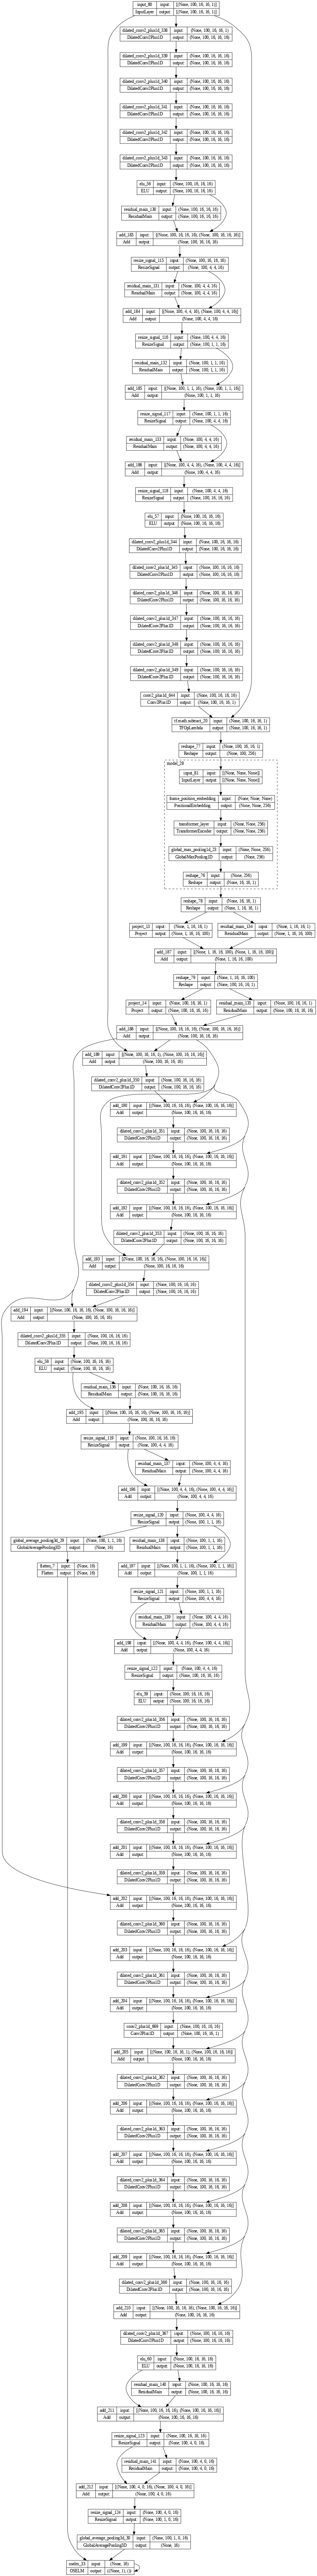

In [ ]:
keras.utils.plot_model(autoencoder_model_v2, expand_nested=True, dpi=60, show_shapes=True)

In [ ]:
autoencoder_model_v2.summary()

Model: "model_27"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_78 (InputLayer)          [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d_308 (Dila  (None, 100, 16, 16,  4912       ['input_78[0][0]']               
 tedConv2Plus1D)                 16)                                                              
                                                                                                  
 dilated_conv2_plus1d_309 (Dila  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d_308[0][0]'
 tedConv2Plus1D)                 16)                             ]                         

In [ ]:
# oselm = OSELM(input_size=16, output_size=1, hidden_layer_size=128)
# analyzer = SignalAnalyzer(sequence_length=100, embed_dim=256)
#
# # Define o modelo completo
# inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))
#
# # Chama o modelo a primeira vez
# latent = encoder_model(inputs)
# reconstructed = decoder_model(latent)
# # Calcula a diferença entre o sinal de entrada e o sinal reconstruído
# diff = tf.keras.layers.Subtract()([inputs, reconstructed])
# # Alimenta a diferença para o SignalAnalyzer
# analysis = analyzer_model(diff)
# analysis = add_residual_block(output, 16, (18, 3, 3))
# analysis = ResizeSignal(analysis.shape[2] // 16, analysis.shape[3] // 16)(x)
# latent = latent + analysis
# latent = layers.GlobalAveragePooling3D()(latent)
#
# # Chama o modelo a segunda vez
# latent_ = encoder_model(reconstructed)
# latent_ = layers.GlobalAveragePooling3D()(latent_)
# outputs_1, _ = oselm(latent_)
# outputs_2, loss = oselm(latent, outputs_1, flag=True)
#
# # Cria o modelo
# nonsupervised = tf.keras.Model(inputs, [reconstructed, outputs_2])

In [ ]:
# keras.utils.plot_model(nonsupervised, expand_nested=True, dpi=60, show_shapes=True)